In [12]:
from typing import TypedDict, Optional
from dotenv import load_dotenv

from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI

In [13]:
load_dotenv()

True

In [14]:
model = ChatGoogleGenerativeAI(model='gemini-flash-lite-latest')

In [15]:
class LLMState(TypedDict):
    question: str
    answer: Optional[str]

In [16]:
def llm_qa(state: LLMState) -> dict:
    # 1. extract question from state
    question = state["question"]

    # 2. form a prompt
    prompt = f"Answer the following question clearly and concisely:\n\n{question}"

    # 3. ask that question to the LLM
    response = model.invoke(prompt)

    # 4. update the answer in the state
    return {"answer": response.content}

In [17]:
# create graph
graph = StateGraph(LLMState)

# add node (node_name, function)
graph.add_node("llm_qa", llm_qa)

# add edges
graph.add_edge(START, "llm_qa")
graph.add_edge("llm_qa", END)

# compile graph
workflow = graph.compile()

In [18]:
# execute the graph
initial_state = {"question": "What is an AI Agent in simple terms?"}

final_state = workflow.invoke(initial_state)

print("Question:", final_state["question"])
print("\nAnswer:\n", final_state["answer"])

Question: What is an AI Agent in simple terms?

Answer:
 [{'type': 'text', 'text': 'An **AI Agent** is an artificial intelligence that can perceive its environment, make decisions, and take actions on its own to achieve a specific goal, with little to no human intervention. \n\nWhile a traditional AI tool simply responds to a prompt (like answering a question), an AI agent can plan a series of steps and use various tools to complete a complex task from start to finish.', 'extras': {'signature': 'EmAKXgFpFH0TQ/wsDpq5IIuu8qL+ENJPT9wcLM3PYhI0ZnYqmtTYF8D0eVP4iHysbtNxUCfS1lesufykbO1AoLJUcyUPqzAMRRlR+Q3cfAKlsXqsIuItexEMwNTwIWoix1Q='}}]


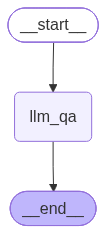

In [19]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())